In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

In [2]:
spam_messages = [
    "Congratulations! You have won a Rs 25,00,000 lottery in the KBC Lucky Draw. Call 9876543210 now to claim your prize.",
    "URGENT: Your SBI account will be blocked today. Update your KYC immediately at http://sbi-kyc-update.xyz",
    "Dear customer, your PAN card is not linked. Click bit.ly/pan-link-now to avoid penalty of Rs 10,000.",
    "You have been selected for a FREE iPhone 15! Claim now: http://free-iphone-winner.top Limited offer!",
    "Get a pre-approved personal loan of Rs 5 lakh in 10 minutes. No documents needed. Apply now: loan-fast.in",
    "WINNER!! As a valued network customer you have been selected to receive a 900 pound prize reward. Call 09061701461 to claim.",
    "Your electricity will be disconnected tonight at 9:30 PM due to unpaid bill. Call 8800123456 immediately to avoid disconnection.",
    "Earn Rs 5000 daily from home! Just like and share videos. Join our Telegram group now: t.me/earnfast123",
    "Your Paytm KYC has expired. Your wallet will be suspended in 24 hours. Verify here: paytm-verify.co",
    "FREE entry in 2 a weekly competition to win FA Cup final tickets. Text FA to 87121 to receive entry question.",
    "Dear user, you have received a cashback of Rs 2,500. Click here to accept: http://cashback-claim.site/upi",
    "Your Amazon order is on hold. Confirm your delivery address and pay Rs 49 fee: amzn-delivery-fix.com",
    "Hot singles in your area want to chat tonight! Reply YES to 5656 for free. T&C apply.",
    "CONGRATULATIONS! Your number has won 1,000,000 in the Microsoft International Lottery. Send your bank details to claim.",
    "Work from home and earn 30,000 per month. Part time job, no experience needed. WhatsApp 9812345678 to join.",
    "Final notice: Your credit card reward points worth Rs 8,450 will expire today. Redeem now at hdfc-rewards-india.com",
    "You are pre-selected for a Rs 10 lakh credit limit upgrade. Share your OTP to activate the offer.",
    "Your Netflix subscription has been suspended. Update payment details immediately: netflix-billing-help.xyz",
    "Claim your free recharge of Rs 599 now! Offer valid for next 2 hours only. Click http://jio-free-recharge.top",
    "Urgent!! Your parcel could not be delivered. Pay customs charge of Rs 99 to release it: http://india-post-track.info",
    "Dear sir, I am a prince from Nigeria and need your help to transfer 15 million dollars. You will get 30 percent. Reply with account number.",
    "Win a brand new bike! Just answer 3 simple questions and share this message with 10 friends. Click here now.",
    "Your bank account is under review. Send your debit card number and PIN to verify your identity.",
    "Tired of debt? Get instant loan approval with bad credit. 100% guaranteed. Call now 1800-999-777.",
    "Bitcoin investment opportunity! Double your money in 7 days guaranteed. Invest Rs 10,000 and get Rs 20,000. Join now.",
    "Last chance! 80% OFF on all branded watches today only. Buy now at http://luxury-watch-deals.shop before stock ends.",
    "Your Aadhaar is linked to illegal activity. Call this number immediately to avoid arrest: 9988776655.",
    "Get 5 GB free data every day for a year. Forward this message to 20 contacts and click the link to activate.",
    "You have 1 new voice message waiting. Listen now: http://voicemail-secure.click/inbox",
    "SIX chances to win CASH! From 100 to 20,000 pounds txt CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply.",
    "Income Tax Dept: You are eligible for a refund of Rs 15,490. Submit your bank details at incometax-refund-gov.in",
    "Free gift for you! Your mobile number has been chosen as a lucky winner. Reply WIN to 56789 to claim your reward.",
    "Meet rich and beautiful women near you. Join now for free and start chatting. Click http://date-now-india.club",
    "Your KYC verification is pending. Account will be frozen. Click link and enter your net banking password.",
    "Make money online with our trading bot! 300% returns weekly. Limited seats left. Message us on WhatsApp today.",
    "Dear student, you are selected for a Rs 50,000 scholarship. Pay Rs 500 registration fee to claim: scholar-grant.in",
    "ALERT: Suspicious login detected on your Google account. Verify now or your account will be deleted: g00gle-security.xyz",
    "Congrats! You are our 1,000,000th visitor. Claim your free gift card of Rs 5,000 here: http://giftcard-india.win",
    "Buy cheap medicines without prescription. Viagra, painkillers, weight loss pills. Fast delivery. Order now!",
    "Your SIM card will be deactivated in 2 hours. Complete re-verification by calling 7766554433 right now.",
    "You have a pending refund from Flipkart of Rs 1,299. Click to receive money in your account: flipkart-refunds.top",
    "Special offer for you: Rs 0 processing fee loan, instant approval, money in 5 minutes. Download our app: quick-cash-app.in",
    "Hello dear, I am lonely widow with 8 million dollars. I want to donate it to you. Please reply urgently.",
    "Free ringtone! Text TONE to 80082 now to get your free polyphonic ringtone. Subscription Rs 30 per week.",
    "Your cab booking reward of Rs 750 is waiting. Click link to claim before it expires in 1 hour.",
    "IMPORTANT: Your ATM card is blocked. To unblock, call our customer care at 9090909090 and share the 6 digit code you receive.",
    "Join our VIP stock tips group. 100% sure shot calls, daily profit guaranteed. Pay Rs 999 and get access now.",
    "You have won a free trip to Dubai! Confirm your passport details and pay Rs 2,000 processing charges to book your tickets.",
    "Dear customer, a fine of Rs 1,000 has been issued for your vehicle. Pay now to avoid court notice: echallan-pay.in",
    "Lose 10 kg in 10 days without exercise! Miracle weight loss tea. Order now and get 70% discount. Limited stock.",
    "We tried to deliver your package but nobody was home. Reschedule by paying a small fee at http://courier-redeliver.xyz",
    "Hi, this is HR from Amazon. Earn Rs 3,000 per day by rating products. Send your name and age on WhatsApp to start today.",
    "Your WhatsApp will expire today. Click here to renew your subscription for Rs 99 per year or lose your account.",
    "Get your CIBIL score fixed in 24 hours! Remove all defaults. Pay Rs 1,500 now. Guaranteed result. Call 9123456780.",
    "Exclusive! Unlock free recharge on every Rs 10 spent. Download this APK now and start earning cash daily.",
    "Thank you for shopping. You are eligible for a free Rs 3,000 voucher. Just complete this short survey: http://survey-reward.top",
    "Your UPI ID has been selected for a Rs 5,000 reward. Enter your UPI PIN to receive the money now.",
    "Act now! Cheap car insurance quote in 2 minutes. Save up to 70 percent. Click here for a free quote.",
    "Your Instagram account violated copyright rules and will be removed. Appeal now using this link: insta-appeal-center.com",
    "Free 3 months Amazon Prime for you! Offer ends tonight. Claim at http://prime-free-gift.click",
    "Cash prize of Rs 50,000 is waiting for you. Send Rs 200 as tax to the account number given to receive it.",
    "Hurry! Gold coins at half price today only. Book now by paying advance. Call 8899001122.",
    "A job is waiting for you at Google India. Salary 80,000. Pay Rs 3,500 for interview slot booking at careers-google-india.co",
    "Dear user, your Gas subsidy of Rs 1,200 is pending. Click and enter bank details to receive: lpg-subsidy-gov.top",
    "Unlimited free calls for lifetime! Just click the link and install our app. Offer for first 1000 users only.",
    "Win 1 crore in our online rummy tournament! Sign up bonus Rs 500 free. Play now: rummy-rich-win.com",
    "Your electricity KYC is incomplete. Download the app from this link to update, else power cut in 2 hours.",
    "Your parcel from DHL has a pending customs duty. Click the link and pay immediately to avoid return.",
    "Exclusive crypto airdrop for you! Connect your wallet here to claim 5000 free tokens before they run out.",
    "You've been chosen for a government housing scheme. Pay Rs 5,000 registration now to confirm your flat allotment.",
    "Dear customer, update your PAN details today to avoid account suspension. Click here: http://bank-pan-update.in",
    "Get paid to watch ads! Earn Rs 1,000 per day on your phone. Register free now at ad-earn-india.xyz",
    "Congratulations, your mobile number won Rs 12 lakh in the Jio Lucky Draw. WhatsApp 9000011111 with your name and address.",
    "Last reminder: your Airtel bill is overdue. Pay now at airtel-pay-quick.info to avoid disconnection of services.",
    "You are shortlisted for a free laptop under the PM scheme. Send Aadhaar number and pay Rs 300 delivery fee.",
    "Instant loan, no CIBIL check, no income proof. Receive money in 5 minutes on your UPI. Click to apply: easy-loan-now.in",
    "Dear user, you have 3 unread messages from a girl who likes you. Click to read them for free.",
    "Claim your free sample today! Just pay shipping of Rs 49. Enter your card details to receive your gift box.",
]

ham_messages = [
    "Hey, are we still meeting at the library at 4 pm today?",
    "Mom said dinner is at 8. Can you pick up some milk on your way home?",
    "Please submit the DBMS assignment by Friday 5 pm on the college portal.",
    "Your Swiggy order #48213 is out for delivery and will reach you in 15 minutes.",
    "Can you send me the notes for yesterday's operating systems lecture?",
    "Happy birthday Riya! Hope you have an amazing day. Party at my place on Saturday.",
    "Rs 500 has been credited to your account via UPI from Rahul. Available balance Rs 3,420.",
    "The class tomorrow has been moved to Room 304. Please inform others in the section.",
    "I'll be late by 10 minutes, traffic near ITO is terrible.",
    "Did you finish the lab record? Sir is checking it tomorrow morning.",
    "Your OTP for logging in to the college ERP is 482913. Do not share it with anyone. Valid for 5 minutes.",
    "Let's study together tonight for the mid-sem exam. Can you come to my room around 7?",
    "Reminder: your dentist appointment is on Tuesday at 11:30 AM at Sector 12 clinic.",
    "Thanks for helping me with the project yesterday. I really appreciate it.",
    "Bro, are you coming for the cricket match this evening? We need one more player.",
    "Your Uber ride is arriving in 3 minutes. Driver Suresh, DL 3C 4567, white Swift Dzire.",
    "Papa will pick you up from the station. Train number 12002 reaches at 6:40 am.",
    "Team meeting at 3 pm in the conference room. Please bring your progress reports.",
    "Can you share the PPT for tomorrow's presentation? I need to add my slides.",
    "Your electricity bill of Rs 1,240 for October has been generated. Due date is 20 November.",
    "Good luck for your interview tomorrow! You will do great, just stay calm.",
    "I reached home safely. Will call you after dinner.",
    "The library will remain closed on Sunday due to the holiday. Normal timings resume Monday.",
    "We are having a family function this weekend. Please come with mummy and papa.",
    "Hi sir, I have uploaded the assignment on the portal. Kindly check and confirm.",
    "Your Amazon order of Boat Earphones has been delivered. Hope you like it. Rate your experience in the app.",
    "What time does the movie start? I will book the tickets for all of us.",
    "Don't forget to carry your ID card tomorrow, the guard is checking at the gate.",
    "Lunch at the canteen? I'm starving after that two hour lab.",
    "Your monthly statement for account ending 4417 is now available in the app.",
    "Our flight is delayed by 40 minutes. New departure time is 7:25 pm.",
    "Can you lend me your calculator for the exam? I forgot mine at home.",
    "Congratulations on getting the internship! Let's celebrate this weekend.",
    "The placement cell has shared the list of companies visiting next week. Please check the notice board.",
    "Sorry, I missed your call. I was in the lab. Call you back in some time.",
    "Your recharge of Rs 299 is successful. Plan valid for 28 days with 1.5 GB per day.",
    "Aunty called, she said the wedding is on 5th December. Keep the date free.",
    "Did you see the match last night? That last over was unbelievable!",
    "Reminder from Dr. Mehta's office: your appointment is confirmed for Thursday at 10 am.",
    "I am sending the photos from the trip on Google Drive. Check your email.",
    "Hey, can we shift the group project meeting to Wednesday? I have a viva on Tuesday.",
    "Your parcel from Flipkart has been shipped and will be delivered by Monday.",
    "Please bring a printed copy of your resume for the campus drive tomorrow.",
    "Thank you for attending the workshop. The certificate will be shared by email next week.",
    "Meet me near the main gate at 9. We will go to the seminar together.",
    "The exam datesheet has been uploaded on the university website. Please check your schedule.",
    "Remember to water the plants while I'm away. I will be back on Sunday night.",
    "Your cylinder booking is confirmed. Delivery expected within two days.",
    "I'm making pasta for dinner tonight. Want to come over?",
    "Can you please review my code before I push it to GitHub? There is a bug in the login function.",
    "Sir has extended the deadline for the mini project report till next Monday.",
    "Wish you a very happy Diwali! May your home be filled with joy and light.",
    "Rs 1,200 debited from your account for Zomato order. If not you, contact your bank.",
    "Class representative meeting at 2 pm in the seminar hall. Attendance is compulsory.",
    "Did you get the bus pass renewed? Last date is tomorrow.",
    "I think we should use Flask for the backend and keep the model in a separate file.",
    "Mom, I have transferred the rent. Please check and confirm.",
    "Your doctor has recommended a follow up test next week. Please carry your previous reports.",
    "Hi, this is Aman from the cricket club. Practice session is on Saturday at 6 am.",
    "I tried calling you twice. Is everything alright? Call me when you are free.",
    "The seminar on cloud computing is at 11 am in the auditorium. Entry is free for all students.",
    "Please find attached the minutes of yesterday's meeting. Let me know if anything is missing.",
    "Your train PNR 2456789012 is confirmed. Coach B2, seat 34. Happy journey.",
    "My laptop charger is not working. Can I borrow yours for the evening?",
    "Let's go for a walk after dinner, I need a break from studying.",
    "Your library book is due on 18 November. Please return or renew it to avoid a late fee of Rs 2 per day.",
    "Hope you are feeling better today. Take rest and drink plenty of water.",
    "Thanks bhaiya, the food was great. Will order again next week.",
    "Your internet bill payment of Rs 799 was received. Thank you for staying with us.",
    "We won the quiz today! Everyone is meeting at the canteen at 5 to celebrate.",
    "Can you teach me how to use Git branches? I keep getting merge conflicts.",
    "The wifi password for the hostel has changed. Ask the warden for the new one.",
    "Don't forget our project demo is at 10 am sharp. Keep the laptop charged and the code ready.",
    "Your Ola ride has been booked. Pickup in 5 minutes from Gate 2.",
    "It's raining heavily here, so I may reach late. Start the discussion without me.",
    "Anil sir wants everyone to submit the survey form before Wednesday. The link is in the class group.",
    "Just landed in Mumbai. The weather is nice. Will message you once I reach the hotel.",
]

df = pd.DataFrame(
    [("spam", t) for t in spam_messages] + [("ham", t) for t in ham_messages],
    columns=["label", "text"],
)

# Optional: use your own CSV (columns: label, text)
USE_UPLOADED_CSV = False
if USE_UPLOADED_CSV:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
    df["label"] = df["label"].str.strip().str.lower()

df = df.dropna().drop_duplicates(subset=["text"]).reset_index(drop=True)
print(df["label"].value_counts())
df.sample(5, random_state=1)

label
spam    78
ham     77
Name: count, dtype: int64


,label,text
117,ham,I am sending the photos from the trip on Googl...
75,spam,"Instant loan, no CIBIL check, no income proof...."
51,spam,"Hi, this is HR from Amazon. Earn Rs 3,000 per ..."
31,spam,Free gift for you! Your mobile number has been...
35,spam,"Dear student, you are selected for a Rs 50,000..."


In [3]:
URL_RE = re.compile(
    r"(https?://\S+|www\.\S+|\b(?:bit\.ly|t\.me)/\S+"
    r"|\b[a-z0-9-]+\.(?:com|in|xyz|top|click|site|shop|win|club|info|co|link|online)\b\S*)",
    re.I,
)
LONG_NUMBER_RE = re.compile(r"\b\d[\d-]{6,}\d\b")
MONEY_RE = re.compile(r"(?:rs\.?|inr|₹|\$|£)\s?\d[\d,]*", re.I)
PLACEHOLDER_LABELS = {"linkx": "link", "phonex": "phone / long number", "moneyx": "money amount"}
DISPLAY_SKIP = {"to", "the", "a", "is", "in", "of", "at", "and", "for", "on", "you", "your", "it", "be", "are", "can"}


def clean_text(text):
    text = str(text).lower()
    text = URL_RE.sub(" linkx ", text)
    text = MONEY_RE.sub(" moneyx ", text)
    text = LONG_NUMBER_RE.sub(" phonex ", text)
    return text


def build_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=5.0)),
    ])


FLAG_RULES = [
    ("Contains a link", re.compile(URL_RE.pattern, re.I)),
    ("Creates urgency", re.compile(r"\b(urgent|immediately|hurry|last chance|final notice|act now|expires?|within \d+ hours?|today only|right now|tonight)\b", re.I)),
    ("Promises a prize or free money", re.compile(r"\b(won|winner|lottery|prize|free|cashback|reward|refund|lucky|guaranteed)\b", re.I)),
    ("Asks for private details", re.compile(r"\b(otp|pin|password|cvv|kyc|aadhaar|pan card|card number|bank details)\b", re.I)),
    ("Tells you to call or message an unknown number", re.compile(r"\b(call|whatsapp|text|reply)\b.{0,40}\d{5,}", re.I)),
    ("Asks you to pay a small fee", re.compile(r"\b(pay|fee|charge|registration)\b.{0,30}\d", re.I)),
]


def red_flags(text):
    return [name for name, pattern in FLAG_RULES if pattern.search(text)]


def verdict_for(p_spam):
    if p_spam >= 0.65:
        return "spam"
    if p_spam >= 0.40:
        return "suspicious"
    return "safe"


def explain(model, text, top_n=6):
    """Terms that pushed the score towards spam or towards safe (coefficient x TF-IDF value)."""
    tfidf, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    vec = tfidf.transform([text])
    names = tfidf.get_feature_names_out()
    coefs = clf.coef_[0]
    contributions = [
        (names[i], float(coefs[i] * vec[0, i]))
        for i in vec.nonzero()[1]
        if not set(names[i].split()) <= DISPLAY_SKIP
    ]
    contributions.sort(key=lambda item: item[1], reverse=True)
    label = lambda term: " ".join(PLACEHOLDER_LABELS.get(p, p) for p in term.split())
    spammy = [(label(t), t) for t, w in contributions if w > 0][:top_n]
    safe = [(label(t), t) for t, w in reversed(contributions) if w < 0][:top_n]
    return spammy, safe


def predict(model, text):
    p_spam = float(model.predict_proba([text])[0][list(model.classes_).index("spam")])
    spammy, safe = explain(model, text)
    return {"verdict": verdict_for(p_spam), "spam_probability": p_spam,
            "red_flags": red_flags(text), "spammy_terms": spammy, "safe_terms": safe}

              precision    recall  f1-score   support

         ham       1.00      0.89      0.94        19
        spam       0.91      1.00      0.95        20

    accuracy                           0.95        39
   macro avg       0.95      0.95      0.95        39
weighted avg       0.95      0.95      0.95        39



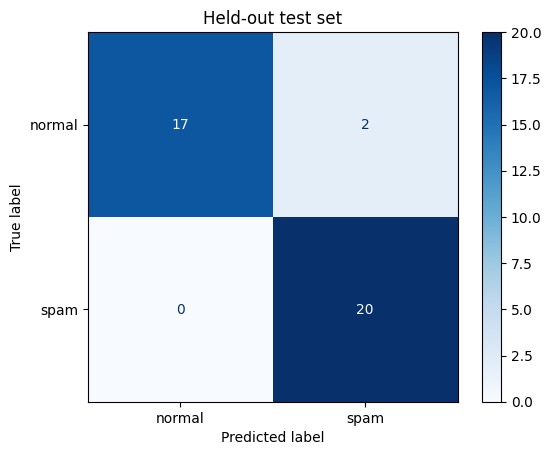

5-fold cross-validated macro F1: 0.927 (+/- 0.067)


In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.25, stratify=df["label"], random_state=42
)

model = build_pipeline().fit(x_train, y_train)
pred = model.predict(x_test)

print(classification_report(y_test, pred))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=["ham", "spam"]),
                       display_labels=["normal", "spam"]).plot(cmap="Blues")
plt.title("Held-out test set")
plt.show()

cv = cross_val_score(build_pipeline(), df["text"], df["label"],
                     cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="f1_macro")
print(f"5-fold cross-validated macro F1: {cv.mean():.3f} (+/- {cv.std():.3f})")

# Final model learns from every message
model = build_pipeline().fit(df["text"], df["label"])

In [5]:
#@title Message to check { display-mode: "form" }
message = "URGENT: Your SBI account will be blocked today. Update your KYC immediately at http://sbi-kyc-update.xyz"  #@param {type:"string"}

import html
from IPython.display import HTML, display

STYLE = {
    "spam": ("Likely spam", "#c4161c", "#fdecea", "Do not click links or share codes. Delete or report the message."),
    "suspicious": ("Be careful", "#93560a", "#fdf0d5", "Some parts look off. Check with the sender through another channel before you act."),
    "safe": ("Looks safe", "#067647", "#e3f5ec", "Nothing alarming found. Still, never share an OTP or PIN with anyone."),
}


def show_result(message):
    r = predict(model, message)
    title, color, bg, tip = STYLE[r["verdict"]]
    pct = round(r["spam_probability"] * 100)
    marked = {w for _, raw in r["spammy_terms"] for w in raw.split()}
    parts = re.split(r"(\w+)", message)
    body = "".join(
        f"<mark style='background:#ffe066'>{html.escape(p)}</mark>" if p.lower() in marked else html.escape(p)
        for p in parts
    )
    flags = "".join(f"<li>{html.escape(f)}</li>" for f in r["red_flags"]) or "<li>None of the usual warning signs.</li>"
    up = " ".join(f"<span style='background:#fdecea;color:#c4161c;padding:2px 8px;border-radius:10px'>{html.escape(t)}</span>" for t, _ in r["spammy_terms"])
    down = " ".join(f"<span style='background:#e3f5ec;color:#067647;padding:2px 8px;border-radius:10px'>{html.escape(t)}</span>" for t, _ in r["safe_terms"])
    display(HTML(f"""
    <div style='font-family:sans-serif;max-width:640px;border:2px solid #101828;border-radius:14px;padding:16px;color:#101828;background:#fff'>
      <div style='display:inline-block;font-weight:800;font-size:22px;color:{color};background:{bg};border:3px solid {color};border-radius:8px;padding:4px 14px'>{title}</div>
      <p>Spam score: <b>{pct} out of 100</b></p>
      <div style='background:#f1f4f8;border-radius:10px;padding:10px;white-space:pre-wrap'>{body}</div>
      <h4>Warning signs found</h4><ul>{flags}</ul>
      <h4>Words that raised the score</h4><p>{up or "None"}</p>
      <h4>Words that lowered it</h4><p>{down or "None"}</p>
      <p style='color:#475467'>{tip}</p>
    </div>"""))


show_result(message)

In [6]:
examples = [
    "Congratulations! You have won a Rs 25,00,000 lottery. Call 9876543210 now to claim your prize.",
    "Your Swiggy order #48213 is out for delivery and will reach you in 15 minutes.",
    "Class is shifted to Room 304 tomorrow. Please inform everyone in the section.",
    "Your OTP for ERP login is 482913. Do not share it with anyone.",
    "Share your OTP to get Rs 5000 cashback immediately",
]
rows = []
for text in examples:
    r = predict(model, text)
    rows.append({"verdict": r["verdict"], "spam score": round(r["spam_probability"] * 100), "message": text[:70]})
pd.DataFrame(rows)

,verdict,spam score,message
0,spam,91,"Congratulations! You have won a Rs 25,00,000 l..."
1,safe,21,Your Swiggy order #48213 is out for delivery a...
2,safe,15,Class is shifted to Room 304 tomorrow. Please ...
3,safe,27,Your OTP for ERP login is 482913. Do not share...
4,spam,77,Share your OTP to get Rs 5000 cashback immedia...
